# Previsão de renda

### 4 elementos importantes
- Esse notebook
- Streamlit com as análises
- Seu Github com o projeto
- Vídeo no readme do github mostrando o streamlit

## Etapa 1 CRISP - DM: Entendimento do negócio




O objetivo deste projeto de Ciência de Dados é desenvolver um modelo capaz de estimar a renda dos clientes com base em suas características disponíveis na base de dados.

Essa previsão pode auxiliar a empresa na segmentação de seus clientes e na definição de estratégias mais adequadas para diferentes perfis. A partir da renda estimada e de outras características do cliente, a empresa poderá identificar quais produtos ou serviços são mais compatíveis com sua realidade financeira e suas necessidades.

Dessa forma, o modelo poderá apoiar decisões comerciais, melhorar a personalização das ofertas e contribuir para um atendimento mais direcionado a cada cliente.

## Etapa 2 Crisp-DM: Entendimento dos dados

Nesta etapa será realizada a exploração da base de dados utilizada no projeto, com o objetivo de compreender sua estrutura, as variáveis disponíveis, seus tipos, possíveis valores ausentes e a distribuição dos dados.

Inicialmente será feita uma análise individual das variáveis e, posteriormente, serão avaliadas possíveis relações entre as características dos clientes e a variável de interesse do projeto, a renda.

### Dicionário de dados

| Variável | Descrição | Tipo |
|---|---|---|
| `data_ref` | Data de referência da coleta das informações | Data |
| `id_cliente` | Código de identificação do cliente | Identificador |
| `sexo` | Sexo do cliente | Categórica |
| `posse_de_veiculo` | Indica se o cliente possui veículo | Categórica / Booleana |
| `posse_de_imovel` | Indica se o cliente possui imóvel | Categórica / Booleana |
| `qtd_filhos` | Quantidade de filhos do cliente | Numérica discreta |
| `tipo_renda` | Tipo ou origem da renda do cliente | Categórica |
| `educacao` | Grau de escolaridade do cliente | Categórica |
| `estado_civil` | Estado civil do cliente | Categórica |
| `tipo_residencia` | Tipo de residência do cliente | Categórica |
| `idade` | Idade do cliente | Numérica |
| `tempo_emprego` | Tempo de trabalho no emprego atual | Numérica |
| `qt_pessoas_residencia` | Quantidade de pessoas que residem no domicílio | Numérica |
| `renda` | Renda do cliente em reais | Numérica contínua |




#### Carregando os pacotes


In [1]:
%matplotlib inline

In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from data_profiling import ProfileReport

#### Carregando os dados


In [4]:
renda = pd.read_csv('./input/previsao_de_renda.csv')



Nesta etapa, foi utilizado o **YData Profiling (Profile Report)** para gerar uma análise exploratória automatizada do conjunto de dados, incluindo estatísticas descritivas, distribuições, valores ausentes e relações entre variáveis.

Além do relatório automatizado, foram realizadas análises utilizando **Python e Pandas**, com o objetivo de inspecionar a estrutura dos dados, verificar sua qualidade e aprofundar a compreensão das variáveis.



Inicialmente, serão verificadas as dimensões do dataset, os nomes das colunas, os tipos de dados, os valores ausentes e as principais estatísticas descritivas.

In [4]:
renda.head(5)

,Unnamed: 0,data_ref,id_cliente,sexo,posse_de_veiculo,posse_de_imovel,qtd_filhos,tipo_renda,educacao,estado_civil,tipo_residencia,idade,tempo_emprego,qt_pessoas_residencia,renda
0,0,2015-01-01,15056,F,False,True,0,Empresário,Secundário,Solteiro,Casa,26,6.602740,1.0,8060.34
1,1,2015-01-01,9968,M,True,True,0,Assalariado,Superior completo,Casado,Casa,28,7.183562,2.0,1852.15
2,2,2015-01-01,4312,F,True,True,0,Empresário,Superior completo,Casado,Casa,35,0.838356,2.0,2253.89
3,3,2015-01-01,10639,F,False,True,1,Servidor público,Superior completo,Casado,Casa,30,4.846575,3.0,6600.77
4,4,2015-01-01,7064,M,True,False,0,Assalariado,Secundário,Solteiro,Governamental,33,4.293151,1.0,6475.97


In [5]:
renda.shape

(15000, 15)

In [6]:
renda.columns

Index(['Unnamed: 0', 'data_ref', 'id_cliente', 'sexo', 'posse_de_veiculo',
       'posse_de_imovel', 'qtd_filhos', 'tipo_renda', 'educacao',
       'estado_civil', 'tipo_residencia', 'idade', 'tempo_emprego',
       'qt_pessoas_residencia', 'renda'],
      dtype='object')

In [7]:
renda.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             15000 non-null  int64  
 1   data_ref               15000 non-null  object 
 2   id_cliente             15000 non-null  int64  
 3   sexo                   15000 non-null  object 
 4   posse_de_veiculo       15000 non-null  bool   
 5   posse_de_imovel        15000 non-null  bool   
 6   qtd_filhos             15000 non-null  int64  
 7   tipo_renda             15000 non-null  object 
 8   educacao               15000 non-null  object 
 9   estado_civil           15000 non-null  object 
 10  tipo_residencia        15000 non-null  object 
 11  idade                  15000 non-null  int64  
 12  tempo_emprego          12427 non-null  float64
 13  qt_pessoas_residencia  15000 non-null  float64
 14  renda                  15000 non-null  float64
dtypes:

In [8]:
renda.isna().sum()

Unnamed: 0                  0
data_ref                    0
id_cliente                  0
sexo                        0
posse_de_veiculo            0
posse_de_imovel             0
qtd_filhos                  0
tipo_renda                  0
educacao                    0
estado_civil                0
tipo_residencia             0
idade                       0
tempo_emprego            2573
qt_pessoas_residencia       0
renda                       0
dtype: int64

In [9]:
renda.duplicated().sum()

np.int64(0)

In [10]:
renda.describe()

,Unnamed: 0,id_cliente,qtd_filhos,idade,tempo_emprego,qt_pessoas_residencia,renda
count,15000.000000,15000.000000,15000.000000,15000.000000,12427.000000,15000.000000,15000.000000
mean,7499.500000,8304.871400,0.432333,43.882333,7.722635,2.206400,5697.287057
std,4330.271354,4797.780446,0.746631,11.273155,6.711189,0.909792,8266.816289
min,0.000000,1.000000,0.000000,22.000000,0.117808,1.000000,118.710000
25%,3749.750000,4181.000000,0.000000,34.000000,2.973973,2.000000,2026.110000
50%,7499.500000,8297.000000,0.000000,43.000000,6.013699,2.000000,3499.720000
75%,11249.250000,12403.000000,1.000000,53.000000,10.120548,3.000000,6392.167500
max,14999.000000,16649.000000,14.000000,68.000000,42.906849,15.000000,245141.670000


#### Entendimento dos dados - Univariada
Nesta etapa tipicamente avaliamos a distribuição de todas as variáveis. 

In [11]:
prof = ProfileReport(renda, explorative=True, minimal=True)
prof


Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]

100%|██████████| 15/15 [00:00<00:00, 744.83it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

A base analisada possui 15.000 registros e 15 variáveis. Não foram identificadas linhas duplicadas. Entre as variáveis analisadas, apenas `tempo_emprego` apresenta valores ausentes, totalizando 2.573 registros sem informação.

A variável `renda`, que será o alvo do projeto, apresenta grande dispersão. Sua média é consideravelmente superior à mediana e o valor máximo é muito superior aos quartis observados, indicando uma distribuição assimétrica à direita e possível presença de valores extremos.

Também foi identificada a coluna `Unnamed: 0`, que aparenta representar apenas um índice salvo junto ao arquivo original, além de `id_cliente`, que funciona como identificador do cliente. Essas variáveis deverão ser avaliadas posteriormente durante a preparação dos dados.

De maneira geral, a análise univariada permitiu identificar a estrutura da base, possíveis valores ausentes e características importantes das distribuições das variáveis antes da etapa de modelagem.

In [ ]:
prof.to_file('./output/renda_analisys.html')

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

### Entendimento dos dados - Bivariadas




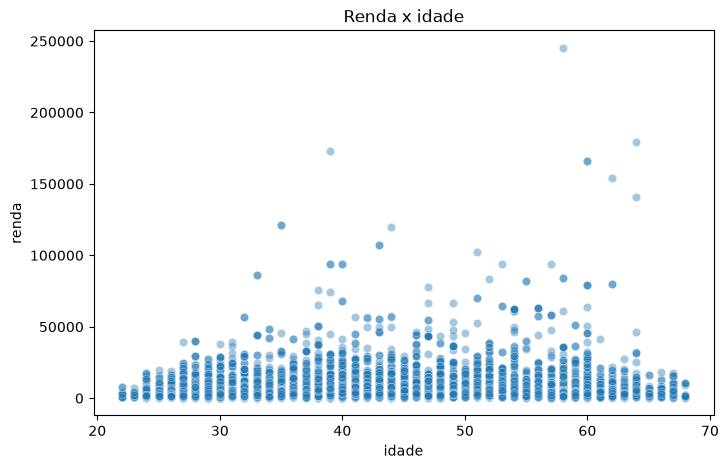

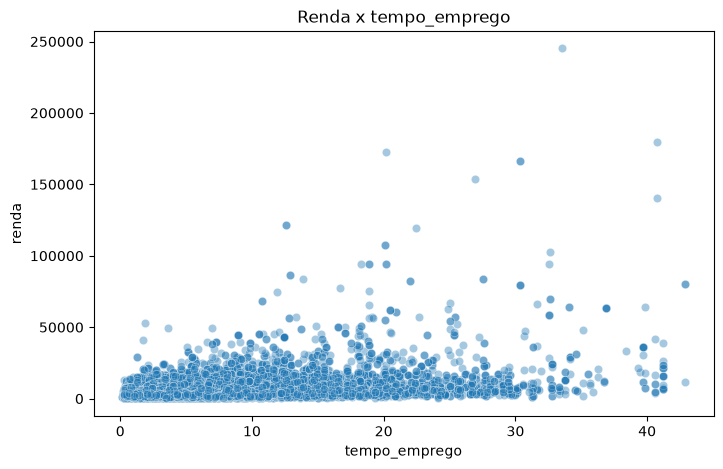

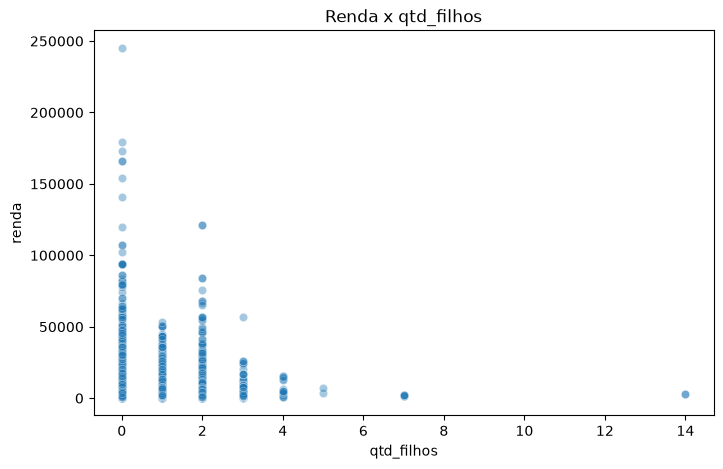

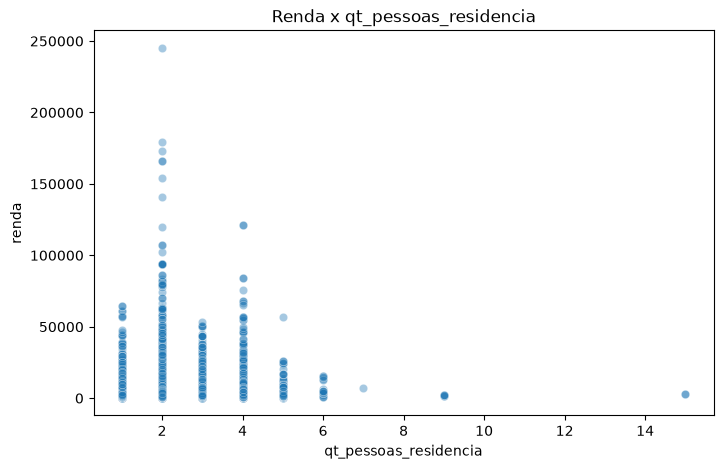

In [5]:
variaveis_numericas = [
    'idade',
    'tempo_emprego',
    'qtd_filhos',
    'qt_pessoas_residencia'
]

for variavel in variaveis_numericas:

    plt.figure(figsize = (8,5))

    sns.scatterplot(
        data=renda,
        x=variavel,
        y='renda',
        alpha = 0.4
    )
    plt.title(
        f'Renda x {variavel}'
    )

    plt.show()
    plt.close()

In [6]:
renda[
    [
        'idade',
        'tempo_emprego',
        'qtd_filhos',
        'qt_pessoas_residencia',
        'renda'
    ]
].corr()

,idade,tempo_emprego,qtd_filhos,qt_pessoas_residencia,renda
idade,1.000000,0.321573,-0.360426,-0.339320,0.022435
tempo_emprego,0.321573,1.000000,-0.063220,-0.065670,0.385013
qtd_filhos,-0.360426,-0.063220,1.000000,0.889777,0.029346
qt_pessoas_residencia,-0.339320,-0.065670,0.889777,1.000000,0.047842
renda,0.022435,0.385013,0.029346,0.047842,1.000000


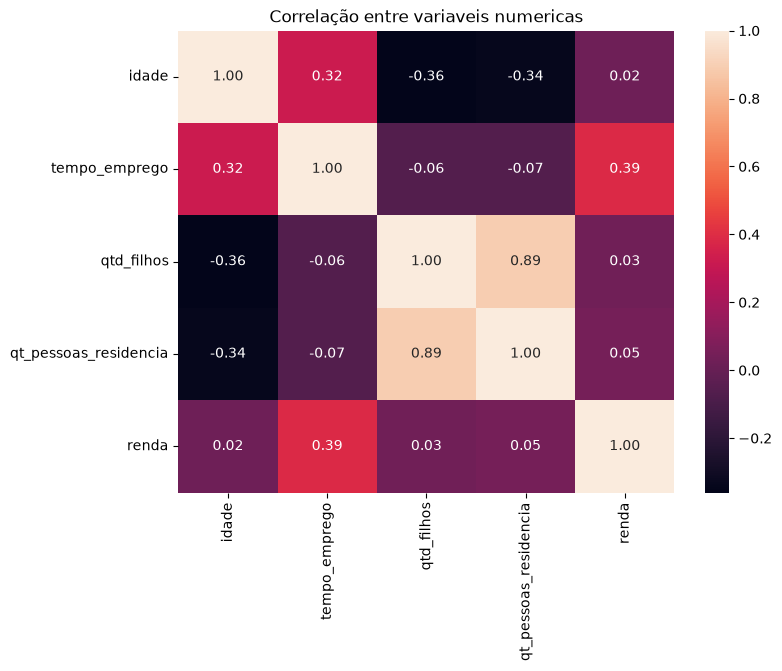

In [7]:
correlacao = renda[
    [
        'idade',
        'tempo_emprego',
        'qtd_filhos',
        'qt_pessoas_residencia',
        'renda'
    ]
].corr()

plt.figure(figsize = (8,6))

sns.heatmap(
    correlacao,
    annot = True,
    fmt = '.2f'
)

plt.title(
    'Correlação entre variaveis numericas'
)

plt.show()
plt.close()


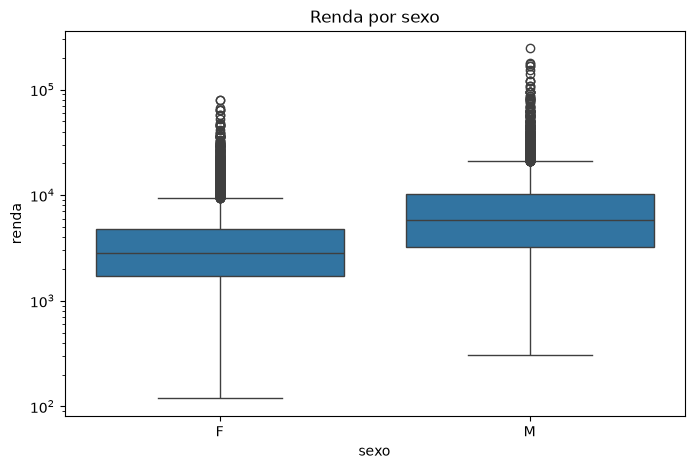

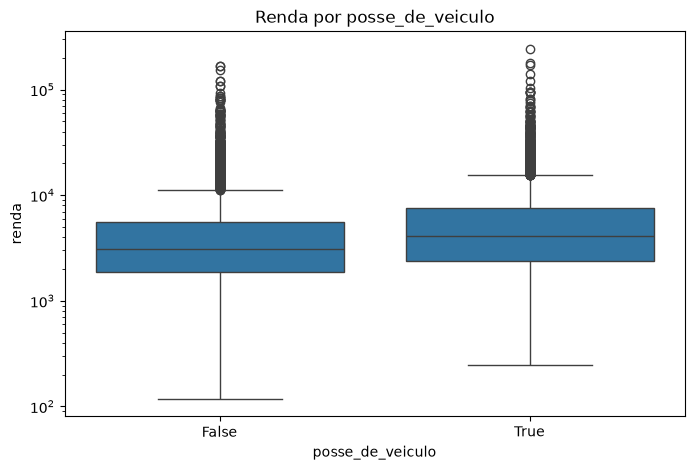

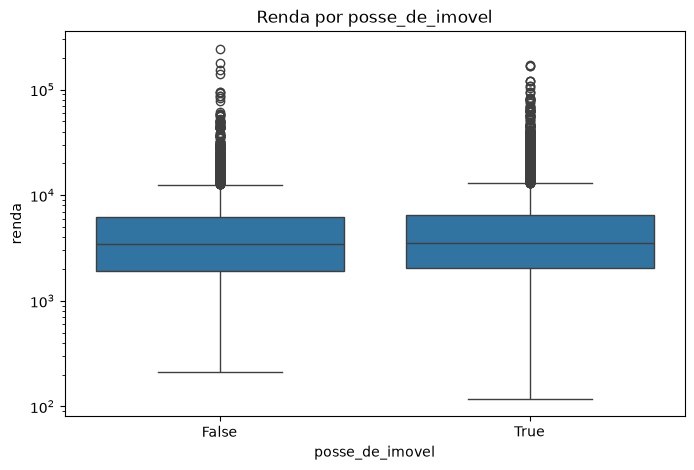

In [8]:
categoricas = [
    'sexo',
    'posse_de_veiculo',
    'posse_de_imovel'
]

for variavel in categoricas:
    plt.figure(figsize = (8,5))

    sns.boxplot(
        data = renda,
        x = variavel,
        y = 'renda'
    )

    plt.title(f'Renda por {variavel}')
    plt.yscale('log')
    plt.show()
    plt.close()

Na análise das variáveis numéricas, `tempo_emprego` apresentou a maior correlação com a renda, com aproximadamente 0,39, indicando uma associação positiva moderada. As variáveis `idade`, `qtd_filhos` e `qt_pessoas_residencia` apresentaram correlações lineares muito próximas de zero com a variável alvo.

Também foi observada uma correlação elevada, de aproximadamente 0,89, entre `qtd_filhos` e `qt_pessoas_residencia`, indicando que essas duas variáveis carregam informações bastante relacionadas entre si. Esse comportamento deverá ser considerado posteriormente durante a etapa de modelagem.

Na análise das variáveis categóricas, os boxplots mostraram diferenças entre alguns grupos. A variável `sexo` apresentou a separação mais evidente, com o grupo masculino apresentando renda mediana superior ao grupo feminino. A posse de veículo também apresentou diferença, com rendas geralmente mais elevadas entre clientes que possuem veículo. Já a posse de imóvel apresentou distribuições bastante semelhantes entre os grupos.

Também foi observada grande quantidade de valores extremos de renda. Por esse motivo, foi utilizada escala logarítmica nos boxplots para facilitar a comparação das distribuições.

Essas relações representam associações observadas na base de dados e não devem ser interpretadas como relações de causa e efeito. A contribuição definitiva de cada variável será avaliada posteriormente durante a modelagem.

## Etapa 3 Preparação dos dados
Nesta etapa os dados serão preparados para a modelagem. Serão removidas variáveis que não possuem valor preditivo direto, tratados os valores ausentes identificados na variável `tempo_emprego`, ajustados os tipos de dados e construída uma transformação da variável renda para reduzir sua elevada assimetria.

Como a base utiliza apenas uma fonte de dados, não será necessária integração com outras bases. As variáveis categóricas serão posteriormente convertidas para um formato adequado ao modelo.


In [9]:
dados = renda.copy()

In [10]:
dados = dados.drop(
    columns = [
        'Unnamed: 0',
        'id_cliente'
    ]
)

In [11]:
dados.columns   

Index(['data_ref', 'sexo', 'posse_de_veiculo', 'posse_de_imovel', 'qtd_filhos',
       'tipo_renda', 'educacao', 'estado_civil', 'tipo_residencia', 'idade',
       'tempo_emprego', 'qt_pessoas_residencia', 'renda'],
      dtype='object')

In [12]:
mediana_tempo_emprego = dados ['tempo_emprego'].median()

dados['tempo_emprego'] = (
    dados['tempo_emprego'].fillna(mediana_tempo_emprego)
)

In [13]:
dados['tempo_emprego'].isna().sum()

np.int64(0)

In [14]:
dados['data_ref'] = pd.to_datetime(
    dados['data_ref'],
    errors = 'coerce'
)

In [15]:
dados['data_ref'].dtype

dtype('<M8[ns]')

In [16]:
import numpy as np
dados['log_renda'] = np.log(
    dados['renda']
)

In [17]:
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15000 entries, 0 to 14999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   data_ref               15000 non-null  datetime64[ns]
 1   sexo                   15000 non-null  object        
 2   posse_de_veiculo       15000 non-null  bool          
 3   posse_de_imovel        15000 non-null  bool          
 4   qtd_filhos             15000 non-null  int64         
 5   tipo_renda             15000 non-null  object        
 6   educacao               15000 non-null  object        
 7   estado_civil           15000 non-null  object        
 8   tipo_residencia        15000 non-null  object        
 9   idade                  15000 non-null  int64         
 10  tempo_emprego          15000 non-null  float64       
 11  qt_pessoas_residencia  15000 non-null  float64       
 12  renda                  15000 non-null  float64       
 13  l

In [18]:
dados.isna().sum()

data_ref                 0
sexo                     0
posse_de_veiculo         0
posse_de_imovel          0
qtd_filhos               0
tipo_renda               0
educacao                 0
estado_civil             0
tipo_residencia          0
idade                    0
tempo_emprego            0
qt_pessoas_residencia    0
renda                    0
log_renda                0
dtype: int64

In [19]:
dados.head()

,data_ref,sexo,posse_de_veiculo,posse_de_imovel,qtd_filhos,tipo_renda,educacao,estado_civil,tipo_residencia,idade,tempo_emprego,qt_pessoas_residencia,renda,log_renda
0,2015-01-01,F,False,True,0,Empresário,Secundário,Solteiro,Casa,26,6.602740,1.0,8060.34,8.994711
1,2015-01-01,M,True,True,0,Assalariado,Superior completo,Casado,Casa,28,7.183562,2.0,1852.15,7.524102
2,2015-01-01,F,True,True,0,Empresário,Superior completo,Casado,Casa,35,0.838356,2.0,2253.89,7.720413
3,2015-01-01,F,False,True,1,Servidor público,Superior completo,Casado,Casa,30,4.846575,3.0,6600.77,8.794942
4,2015-01-01,M,True,False,0,Assalariado,Secundário,Solteiro,Governamental,33,4.293151,1.0,6475.97,8.775854


In [20]:
dados[
    ['renda', 'log_renda']

].describe()

,renda,log_renda
count,15000.000000,15000.000000
mean,5697.287057,8.208275
std,8266.816289,0.883441
min,118.710000,4.776684
25%,2026.110000,7.613873
50%,3499.720000,8.160438
75%,6392.167500,8.762829
max,245141.670000,12.409592


Durante a preparação dos dados foram removidas as variáveis `Unnamed: 0` e `id_cliente`, por representarem respectivamente um índice do arquivo e um identificador do cliente, sem contribuição preditiva direta para o problema.

Os valores ausentes da variável `tempo_emprego` foram preenchidos utilizando sua mediana, preservando os registros da base sem introduzir forte influência de valores extremos. A variável `data_ref` foi convertida para o formato de data e foi criada a variável `log_renda`, com o objetivo de reduzir a assimetria observada na distribuição da renda.

Após os tratamentos realizados, a base permanece com 15.000 registros e não apresenta valores ausentes, estando preparada para a etapa de modelagem.

## Etapa 4: Modelagem
Nesta etapa será construído um modelo de regressão para estimar a renda dos clientes.

Como a variável renda apresenta forte assimetria e valores extremos, será utilizada `log_renda` como variável alvo. Para o primeiro modelo será utilizada Regressão Linear, por ser uma técnica adequada para previsão de uma variável numérica contínua e por servir como modelo de referência para futuras comparações.

Os dados serão divididos em conjuntos de treino e teste, permitindo treinar o modelo em uma parte da base e posteriormente avaliar seu desempenho em dados que não foram utilizados durante o treinamento.


In [21]:
x = dados.drop(
    columns = ['renda',
    'log_renda',
    'data_ref']
)

y = dados['log_renda']

In [22]:
x = pd.get_dummies(
    x,
    drop_first = True,
    dtype = int
)

In [23]:
x.head()

,posse_de_veiculo,posse_de_imovel,qtd_filhos,idade,tempo_emprego,qt_pessoas_residencia,sexo_M,tipo_renda_Bolsista,tipo_renda_Empresário,tipo_renda_Pensionista,...,educacao_Superior incompleto,estado_civil_Separado,estado_civil_Solteiro,estado_civil_União,estado_civil_Viúvo,tipo_residencia_Casa,tipo_residencia_Com os pais,tipo_residencia_Comunitário,tipo_residencia_Estúdio,tipo_residencia_Governamental
0,False,True,0,26,6.602740,1.0,0,0,1,0,...,0,0,1,0,0,1,0,0,0,0
1,True,True,0,28,7.183562,2.0,1,0,0,0,...,0,0,0,0,0,1,0,0,0,0
2,True,True,0,35,0.838356,2.0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
3,False,True,1,30,4.846575,3.0,0,0,0,0,...,0,0,0,0,0,1,0,0,0,0
4,True,False,0,33,4.293151,1.0,1,0,0,0,...,0,0,1,0,0,0,0,0,0,1


In [24]:
x.shape

(15000, 24)

In [26]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42
)

In [27]:
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape)

(12000, 24)
(3000, 24)
(12000,)
(3000,)


In [28]:
from sklearn.linear_model import LinearRegression
modelo = LinearRegression()

### Rodando o modelo


In [30]:
modelo.fit(
    x_train,
    y_train
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](24,)","[ 0.04, 0.09,-0.18,...,-0.08, 0.12, 0.04]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](24,)","['posse_de_veiculo','posse_de_imovel','qtd_filhos',..., 'tipo_residencia_Comunitário','tipo_residencia_Estúdio', 'tipo_residencia_Governamental']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,6.783
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,24
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(24)


In [31]:
y_pred = modelo.predict(
    x_test
)

In [32]:
comparacao = pd.DataFrame({
    'real_log' : y_test,
    'previsto_log' : y_pred
})
comparacao.head()

,real_log,previsto_log
11499,8.154563,7.795909
6475,8.490375,8.197999
13167,10.069437,10.218042
862,6.562388,7.749227
5970,8.377791,8.551630


In [33]:
comparacao['renda_real'] = np.exp(
    comparacao['real_log']
)

comparacao['renda_prevista'] = np.exp(
    comparacao['previsto_log']
)

In [34]:
comparacao[[
    'renda_real' , 'renda_prevista'
]].head(10)

,renda_real,renda_prevista
11499,3479.22,2430.638420
6475,4867.69,3633.672087
13167,23610.27,27392.971083
862,707.96,2319.779287
5970,4349.39,5175.183154
6706,15289.23,2653.765466
3017,1918.32,2608.670578
3781,3724.31,7593.893409
3898,1281.22,1896.539533
2250,5746.69,2554.288443


## Etapa 4.1 - Treinando outros modelos para melhorar a nossa eficacia de previsao e depois fazer a comparação entre modelos criados para chegar em uma conclusão de qual seria mais adequado para usar na nossa respectiva base de dados


In [48]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [49]:
x_train_scaled = scaler.fit_transform(
    x_train
)

x_test_scaled = scaler.transform(
    x_test)

In [50]:
from sklearn.linear_model import Ridge

In [51]:
modelo_ridge = Ridge(
    alpha = 1.0
)

In [52]:
modelo_ridge.fit(
    x_train_scaled,
    y_train
)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [53]:
pred_ridge_log = modelo_ridge.predict(
    x_test_scaled
)

In [54]:
pred_ridge_renda = np.exp(
    pred_ridge_log
)

In [55]:
mae_ridge = mean_absolute_error(
    comparacao['renda_real'],
    pred_ridge_renda
)

rmse_ridge = np.sqrt(
    mean_squared_error(
        comparacao['renda_real'],
        pred_ridge_renda
    )
)

r2_ridge_log = r2_score(
    y_test,
    pred_ridge_log
)

r2_ridge_renda = r2_score(
    comparacao['renda_real'],
    pred_ridge_renda
)

NameError: name 'mean_absolute_error' is not defined

In [ ]:
print(f'Linear R² log: {r2_log:.6f}')
print(f'Ridge R² log: {r2_ridge_log:.6f}')

print(f'Linear R² renda: {r2_renda:.6f}')
print(f'Ridge R² renda: {r2_ridge_renda:.6f}')

Linear R² log: 0.352547
Ridge R² log: 0.352526
Linear R² renda: 0.267737
Ridge R² renda: 0.267707


Apos a analise utilizando o Ridge chegamos a conclusão que ele agiu aproximadamente igual a regressão linear, com isso vamos treinar outro modelo utilizando o Lasso dessa vez, para tentar melhorar o respectivo modelo

In [ ]:
from sklearn.linear_model import Lasso

In [ ]:
modelo_lasso = Lasso(
    alpha=0.001,
    max_iter = 10000
)

In [ ]:
modelo_lasso.fit(
    x_train_scaled,
    y_train
)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.001
,"max_iter max_iter: int, default=1000The maximum number of iterations.",10000
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [ ]:
pred_lasso_log = modelo_lasso.predict(
    x_test_scaled
)

In [ ]:
pred_lasso_renda = np.exp(
    pred_lasso_log
)

In [ ]:
mae_lasso = mean_absolute_error(
    comparacao['renda_real'],
    pred_lasso_renda
)

rmse_lasso = np.sqrt(
    mean_squared_error(
        comparacao['renda_real'],
        pred_lasso_renda
    )
)

r2_lasso_log = r2_score(
    y_test,
    pred_lasso_log
)

r2_lasso_renda = r2_score(
    comparacao['renda_real'],
    pred_lasso_renda
)

print(f'MAE Lasso: R$ {mae_lasso:.2f}')
print(f'RMSE Lasso: R$ {rmse_lasso:.2f}')
print(f'R² Lasso log: {r2_lasso_log:.3f}')
print(f'R² Lasso renda: {r2_lasso_renda:.3f}')

MAE Lasso: R$ 2996.28
RMSE Lasso: R$ 5995.44
R² Lasso log: 0.352
R² Lasso renda: 0.266


In [ ]:
coeficientes_lasso = pd.Series(
    modelo_lasso.coef_,
    index=x.columns
)

coeficientes_lasso.sort_values()

tipo_renda_Pensionista          -0.027616
educacao_Secundário             -0.023313
educacao_Superior incompleto    -0.017326
estado_civil_União              -0.005217
tipo_residencia_Comunitário     -0.004654
estado_civil_Solteiro           -0.003857
tipo_residencia_Casa            -0.003101
qtd_filhos                       0.000000
tipo_residencia_Com os pais      0.002705
tipo_renda_Bolsista              0.004069
educacao_Pós graduação           0.004395
tipo_residencia_Governamental    0.005724
tipo_residencia_Estúdio          0.007802
estado_civil_Separado            0.007861
estado_civil_Viúvo               0.011108
tipo_renda_Servidor público      0.014950
posse_de_veiculo                 0.017369
qt_pessoas_residencia            0.018929
educacao_Superior completo       0.034502
posse_de_imovel                  0.041417
idade                            0.052208
tipo_renda_Empresário            0.067927
sexo_M                           0.368771
tempo_emprego                    0

In [ ]:
(coeficientes_lasso == 0).sum()

np.int64(1)

Depois da analise utilizando o Lasso, visualizamos que ele ficou levemente pior. Mas ele nos ajudou zerando a variavel qntd_filhos, ou seja, ele simplificou um pouco o modelo, removendo uma variável do ponto de vista linear. a A conclusão ate agora é que a regressao linear teve o melhor desempenho ate agora. Vamos testar agora  uma Arvore de decisões.

In [ ]:
from sklearn.tree import DecisionTreeRegressor

In [ ]:
modelo_arvore = DecisionTreeRegressor(
    max_depth = 5,
    min_samples_leaf = 20,
    random_state = 42
)

In [ ]:
modelo_arvore.fit(
    x_train,
    y_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes ma

In [ ]:
pred_arvore_log = modelo_arvore.predict(
    x_test
)

In [ ]:
pred_arvore_renda = np.exp(
    pred_arvore_log
)

In [ ]:
mae_arvore = mean_absolute_error(
    comparacao['renda_real'],
    pred_arvore_renda
)

rmse_arvore = np.sqrt(
    mean_squared_error(
        comparacao['renda_real'],
        pred_arvore_renda
    )
)

r2_arvore_log = r2_score(
    y_test,
    pred_arvore_log
)

r2_arvore_renda = r2_score(
    comparacao['renda_real'],
    pred_arvore_renda
)

print(f'MAE Árvore: R$ {mae_arvore:.2f}')
print(f'RMSE Árvore: R$ {rmse_arvore:.2f}')
print(f'R² Árvore log: {r2_arvore_log:.3f}')
print(f'R² Árvore renda: {r2_arvore_renda:.3f}')

MAE Árvore: R$ 2950.12
RMSE Árvore: R$ 5722.64
R² Árvore log: 0.351
R² Árvore renda: 0.332


In [ ]:
resultados_arvore = []

for profundidade in range(2, 11):

    arvore = DecisionTreeRegressor(
        max_depth=profundidade,
        min_samples_leaf=20,
        random_state=42
    )

    arvore.fit(
        x_train,
        y_train
    )

    pred_log = arvore.predict(
        x_test
    )

    pred_renda = np.exp(
        pred_log
    )

    mae = mean_absolute_error(
        comparacao['renda_real'],
        pred_renda
    )

    rmse = np.sqrt(
        mean_squared_error(  
            comparacao['renda_real'],
            pred_renda
        )
    )

    r2 = r2_score(
        comparacao['renda_real'],
        pred_renda
    )

    resultados_arvore.append({
        'profundidade': profundidade,
        'MAE': mae,
        'RMSE': rmse,
        'R2': r2
    })

In [ ]:
resultados_arvore = pd.DataFrame(
    resultados_arvore
)

resultados_arvore

,profundidade,MAE,RMSE,R2
0,2,3162.203995,6366.145277,0.172903
1,3,2976.883997,5799.981978,0.313475
2,4,2984.652184,5850.280430,0.301516
3,5,2950.121825,5722.636025,0.331663
4,6,2941.016908,5668.413798,0.344268
5,7,2952.878418,5660.131834,0.346183
6,8,2943.686307,5636.593192,0.351610
7,9,2936.182213,5615.259081,0.356509
8,10,2936.884013,5610.413032,0.357619


## Etapa 5 Crisp-DM: Avaliação dos resultados


In [67]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
mae = mean_absolute_error(
    comparacao['renda_real'],
    comparacao['renda_prevista']
)

rmse = np.sqrt(
    mean_squared_error(
        comparacao['renda_real'],
        comparacao['renda_prevista']
    )
)

r2_log = r2_score(
    y_test,
    y_pred
)

r2_renda = r2_score(
    comparacao['renda_real'],
    comparacao['renda_prevista']

)
print(f'MAE : R$ {mae:.2f}')
print(f'RMSE : R$ {rmse:.2f}')
print(f'R² no log da renda: {r2_log:.3f}')
print(f'R² na renda original: {r2_renda:.3f}')

MAE : R$ 2995.94
RMSE : R$ 5990.07
R² no log da renda: 0.353
R² na renda original: 0.268


O modelo de Regressão Linear apresentou MAE de aproximadamente R$ 2.996, indicando que as previsões se afastam da renda real, em média, cerca de R$ 3 mil.

O RMSE foi de aproximadamente R$ 5.990, valor consideravelmente superior ao MAE. Essa diferença indica a presença de alguns erros de previsão elevados, comportamento compatível com a existência de valores extremos de renda identificados durante a análise exploratória.

O R² obtido para o logaritmo da renda foi de aproximadamente 0,35, indicando que o modelo explica cerca de 35% da variabilidade da variável alvo transformada. Após retornar as previsões para a escala original da renda, o R² foi de aproximadamente 0,27.

Os resultados mostram que o modelo consegue capturar parte dos padrões presentes nos dados, porém ainda possui capacidade preditiva limitada. A transformação logarítmica apresentou melhor comportamento que a renda em sua escala original, indicando que foi útil para reduzir o efeito da forte assimetria da variável alvo.

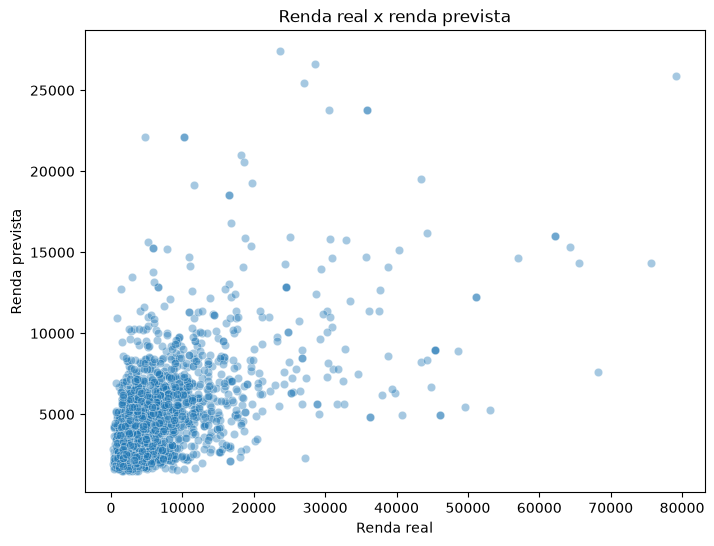

In [ ]:
plt.figure(figsize = (8,6))

sns.scatterplot(
    data = comparacao,
    x='renda_real',
    y = 'renda_prevista',
    alpha = 0.4

)

plt.xlabel("Renda real")
plt.ylabel("Renda prevista")
plt.title("Renda real x renda prevista")

plt.show()
plt.close()

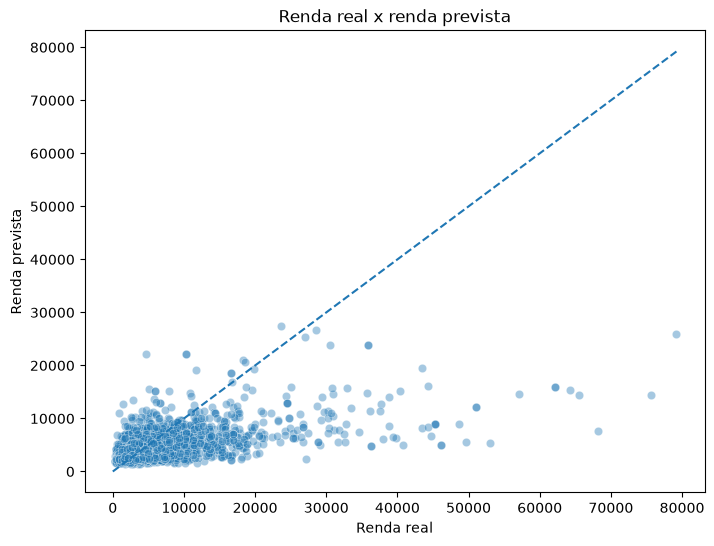

In [ ]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data = comparacao,
    x = 'renda_real',
    y = 'renda_prevista',
    alpha = 0.4
)

limite = max(
    comparacao['renda_real'].max(),
    comparacao['renda_prevista'].max()

)

plt.plot(
    [0,limite],
    [0,limite],
    '--'
)

plt.xlabel('Renda real')
plt.ylabel('Renda prevista')
plt.title('Renda real x renda prevista')
plt.show()
plt.close()

O modelo de Regressão Linear apresentou MAE de aproximadamente R$ 2.996 e RMSE de aproximadamente R$ 5.990. A diferença significativa entre essas métricas indica a existência de erros elevados em alguns registros, principalmente entre clientes com rendas mais altas.

O R² obtido para o logaritmo da renda foi de aproximadamente 0,35, enquanto na escala original da renda foi de aproximadamente 0,27. Dessa forma, o modelo consegue explicar parte da variabilidade da renda, porém ainda apresenta capacidade preditiva limitada.

A análise gráfica entre os valores reais e previstos mostra que o modelo apresenta melhor comportamento nas faixas de renda mais comuns da base, mas tende a subestimar rendas mais elevadas. Esse comportamento é compatível com a forte assimetria e com os valores extremos identificados durante a análise exploratória.

Apesar das limitações, o modelo conseguiu identificar padrões relevantes e pode ser utilizado como modelo de referência para comparações com técnicas mais complexas.

In [36]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

In [37]:
parametros = {
    'max_depth': [3,4,5,6,7,8,10],
    'min_samples_leaf' : [10,20,30,50]
}


In [38]:
arvore_base = DecisionTreeRegressor(
    random_state = 42
)

In [39]:
grid = GridSearchCV(
    estimator = arvore_base,
    param_grid = parametros,
    cv = 5,
    scoring = 'r2',
    n_jobs = -1
)

In [40]:
grid.fit(
    x_train,
    y_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",DecisionTreeR...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'max_depth': [3, 4, ...], 'min_samples_leaf': [10, 20, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'r2'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information

In [41]:
grid.best_params_

{'max_depth': 7, 'min_samples_leaf': 50}

In [42]:
grid.best_score_

np.float64(0.35051857996860153)

In [43]:
melhor_arvore = grid.best_estimator_

In [44]:
pred_melhor_log = melhor_arvore.predict(
    x_test
)

pred_melhor_renda = np.exp(
    pred_melhor_log
)

In [68]:
mae_melhor = mean_absolute_error(
    comparacao['renda_real'],
    pred_melhor_renda
)

rmse_melhor = np.sqrt(
    mean_squared_error(
        comparacao['renda_real'],
        pred_melhor_renda
    )
)


r2_melhor_log = r2_score(
    y_test,
    pred_melhor_log
)

r2_melhor_renda = r2_score(
    comparacao['renda_real'],
    pred_melhor_renda
)
print(f'MAE: R$ {mae_melhor:.2f}')
print(f'RMSE: R$ {rmse_melhor:.2f}')
print(f'R² log: {r2_melhor_log:.3f}')
print(f'R² renda: {r2_melhor_renda:.3f}')


MAE: R$ 2986.93
RMSE: R$ 5848.33
R² log: 0.349
R² renda: 0.302


In [ ]:
grid.best_params_

{'max_depth': 7, 'min_samples_leaf': 50}

In [ ]:
grid.best_score_

np.float64(0.35051857996860153)

Foram comparados modelos de Regressão Linear, Ridge, Lasso e Árvore de Regressão. Entre os modelos testados, a árvore com profundidade máxima 5 e mínimo de 20 observações por folha apresentou o melhor desempenho na escala original da renda, com menor MAE e RMSE e maior R².

In [35]:
from sklearn.ensemble import RandomForestRegressor

In [61]:
modelo_rf = RandomForestRegressor(
    n_estimators = 300,
    max_depth = 8,
    min_samples_leaf = 10,
    random_state = 42,
    n_jobs = 1
)

In [62]:
modelo_rf.fit(
    x_train,
    y_train
)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_

In [63]:
pred_rf_log = modelo_rf.predict(
    x_test
)

In [64]:
pred_rf_renda = np.exp(
    pred_rf_log
)

In [69]:
mae_rf = mean_absolute_error(
    comparacao['renda_real'],
    pred_rf_renda
)

rmse_rf = np.sqrt(
    mean_squared_error(
        comparacao['renda_real'],
        pred_rf_renda
    )
)

r2_rf_log = r2_score(
    y_test,
    pred_rf_log
)

r2_rf_renda = r2_score(
    comparacao['renda_real'],
    pred_rf_renda
)

print(f'MAE Random Forest: R$ {mae_rf:.2f}')
print(f'RMSE Random Forest: R$ {rmse_rf:.2f}')
print(f'R² Random Forest log: {r2_rf_log:.3f}')
print(f'R² Random Forest renda: {r2_rf_renda:.3f}')

MAE Random Forest: R$ 2868.79
RMSE Random Forest: R$ 5625.31
R² Random Forest log: 0.391
R² Random Forest renda: 0.354


In [66]:
importancias = pd.Series(
    modelo_rf.feature_importances_,
    index=x.columns
).sort_values(
    ascending=False
)

importancias.head(10)

tempo_emprego                 0.562666
sexo_M                        0.321325
idade                         0.042732
tipo_renda_Empresário         0.014709
posse_de_imovel               0.009829
educacao_Superior completo    0.008472
qt_pessoas_residencia         0.008388
posse_de_veiculo              0.006850
qtd_filhos                    0.005130
educacao_Secundário           0.004852
dtype: float64

Foram avaliados diferentes modelos de regressão, incluindo Regressão Linear, Ridge, Lasso, Árvore de Regressão e Random Forest.

Entre os modelos avaliados, a Random Forest apresentou o melhor desempenho, com MAE de aproximadamente R$ 2.869, RMSE de aproximadamente R$ 5.625 e R² de 0,354 na escala original da renda. O modelo também apresentou R² de aproximadamente 0,391 para o logaritmo da renda.

Apesar de ainda existir uma parcela relevante da variabilidade da renda que não é explicada pelas variáveis disponíveis, a Random Forest apresentou resultados superiores aos demais modelos testados e foi selecionada como modelo final do projeto.

A análise de importância das variáveis mostrou que `tempo_emprego` e `sexo_M` foram as características mais utilizadas pelo modelo para realizar as previsões. Esse resultado é consistente com padrões previamente observados durante a análise exploratória.

Dessa forma, a Random Forest será utilizada na etapa de implantação, mantendo-se como limitação do projeto o fato de que outras características não disponíveis na base podem ser necessárias para aumentar a capacidade preditiva do modelo.

## Etapa 6 Crisp-DM: Implantação
Após a comparação dos modelos avaliados, a Random Forest foi selecionada como modelo final por apresentar o melhor desempenho geral nas previsões de renda.

Nesta etapa, o modelo será salvo e posteriormente utilizado em uma aplicação desenvolvida com Streamlit. A aplicação permitirá que o usuário informe características de um cliente e obtenha uma estimativa de sua renda.

Dessa forma, o modelo desenvolvido no notebook poderá ser utilizado por meio de uma interface interativa, sem a necessidade de executar manualmente o código de treinamento.

In [71]:
import joblib
from pathlib import Path

In [75]:
pasta_modelo = Path(
    r'C:\Users\VITU\Desktop\Projeto Do curso\projeto 2\output\modelo'
)

pasta_modelo.mkdir(
    parents=True,
    exist_ok=True
)

In [77]:
joblib.dump(
    modelo_rf,
    pasta_modelo / 'random_forest.pkl'
)

['C:\\Users\\VITU\\Desktop\\Projeto Do curso\\projeto 2\\output\\modelo\\random_forest.pkl']

In [78]:
joblib.dump(
    list(x.columns),
    pasta_modelo / 'columns_modelo.pkl'
)

['C:\\Users\\VITU\\Desktop\\Projeto Do curso\\projeto 2\\output\\modelo\\columns_modelo.pkl']

In [79]:
joblib.dump(
    categorias,
    pasta_modelo / 'categorias.pkl'
)

NameError: name 'categorias' is not defined

In [82]:
colunas_categorias = [
    'sexo', 
    'tipo_renda',
    'educacao',
    'estado_civil',
    'tipo_residencia'
]

In [83]:
categorias = {}

for coluna in colunas_categorias:

    categorias[coluna] = (
        dados[coluna]
        .dropna()
        .unique()
        .tolist()
    )

In [84]:
categorias

{'sexo': ['F', 'M'],
 'tipo_renda': ['Empresário',
  'Assalariado',
  'Servidor público',
  'Pensionista',
  'Bolsista'],
 'educacao': ['Secundário',
  'Superior completo',
  'Superior incompleto',
  'Primário',
  'Pós graduação'],
 'estado_civil': ['Solteiro', 'Casado', 'Viúvo', 'União', 'Separado'],
 'tipo_residencia': ['Casa',
  'Governamental',
  'Com os pais',
  'Aluguel',
  'Estúdio',
  'Comunitário']}

In [85]:
joblib.dump(
    categorias,
    pasta_modelo / 'categorias.pkl'
)

['C:\\Users\\VITU\\Desktop\\Projeto Do curso\\projeto 2\\output\\modelo\\categorias.pkl']

In [ ]:
list(
    pasta_modelo.iterdir()
)

[WindowsPath('/.output/modelo/categorias.pkl'),
 WindowsPath('/.output/modelo/columns_modelo.pkl'),
 WindowsPath('/.output/modelo/random_forest.pkl')]

In [ ]:
modelo_teste = joblib.load(
    pasta_modelo / 'random_forest.pkl'
)

modelo_teste

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",300
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_